# 06. Ablasi: Komponen Mana yang Berperan?

**Pertanyaan.** Model CNN + Bi-LSTM (notebook 04 dan 05) memadukan beberapa keputusan rancangan: fungsi *loss*, pembobotan kelas, konteks waktu lewat Bi-LSTM, panjang jendela, dan empat jenis sinyal masukan. Mana di antaranya yang benar-benar menyumbang pada akurasi, dan mana yang hanya tampak penting?

**Mengapa penting.** Di notebook 04 beberapa hal berubah sekaligus (misalnya pembobotan kelas ikut berubah bersama *focal loss*), sehingga sebab dan akibat tidak bisa dipisahkan. Ablasi memperbaikinya dengan mengubah **satu hal per percobaan** terhadap model referensi, lalu mengukur selisihnya pada subjek yang sama. Hasilnya menentukan bagian model mana yang layak dipertahankan, dijelaskan, atau dipertanyakan.

**Data.** 20 subjek Sleep Cassette berusia 25–34 tahun (39 rekaman, 42.307 *epoch* berlabel), yang sama dengan notebook 04. Seluruh percobaan memakai 20 *fold* satu-subjek-uji, dan tiap percobaan diulang dengan tiga *seed*.

**Hasil utama.**
- **Konteks waktu adalah satu-satunya komponen yang terbukti.** Tanpa Bi-LSTM, MF1 turun 2,3 poin per subjek (interval kepercayaan 95% −3,4 sampai −1,4; *p* terkoreksi 0,001). Panjang jendela 10, 20, atau 30 *epoch* memberi hasil yang sama (MF1 80,1 pada ketiganya).
- ***Loss* dan bobot kelas tidak mengubah kualitas keseluruhan.** Keempat kombinasi berada dalam rentang 79,9–80,7 dan tidak ada yang berbeda nyata dari referensi. Bobot kelas hanya menggeser keseimbangan: sensitivitas N1 naik sekitar 10 poin, tetapi *precision*-nya turun dan sensitivitas N2 ikut turun.
- **Menambah sinyal membantu pelan-pelan.** MF1 naik dari 78,3 (satu kanal EEG) ke 80,1 (semua sinyal), jauh lebih landai daripada model *gradient boosting* tanpa konteks (68,4 ke 76,6). Setelah koreksi, tidak ada model dengan sinyal lebih sedikit yang terbukti lebih buruk daripada model lengkap.
- **Pembagian acak per *epoch* menggelembungkan MF1 sebesar 10,2 poin** pada model ini (80,4 menjadi 90,6), dan 7,0 poin pada *baseline*. Angka yang sah hanya yang dibagi per subjek.

Istilah seperti *epoch*, *fold*, *seed*, Macro-F1 (MF1), κ, *bootstrap*, uji Wilcoxon, dan koreksi Holm dijelaskan di tabel istilah notebook 01.

**Peta notebook**

| Bagian | Isi |
|---|---|
| A–C | Daftar percobaan, data, dan pembagian *fold* |
| D | Pemeriksaan model tiap percobaan |
| E | Pelatihan semua percobaan (diulang tiga *seed*) |
| F–G | Hasil keseluruhan dan uji berpasangan per subjek |
| H | *Loss* dan bobot kelas (desain 2×2) |
| I | Konteks waktu dan panjang jendela |
| J | Sinyal masukan, ditambah satu per satu |
| K | Kebocoran data pada model akhir |
| L | Penyimpanan, kesimpulan, keterbatasan, dan catatan teknis |

## A. Daftar percobaan

**Tujuan.** Menetapkan model referensi dan setiap variasinya sebelum ada yang dilatih. Setiap percobaan ("lengan") hanya boleh berbeda dari referensi dalam satu hal, supaya selisih hasilnya bisa dikaitkan ke hal itu saja.

**Input.** Pengaturan model dan pelatihan dari notebook 04 (referensi: *cross-entropy* tanpa bobot kelas, jendela 20 *epoch*), dan daftar variasi berikut.

| Pertanyaan | Percobaan | Yang diubah |
|---|---|---|
| *Loss* (2×2) | *cross-entropy* berbobot; *focal* tanpa bobot; *focal* berbobot | γ (0 atau 2) dan bobot kelas (tidak atau ya) |
| Konteks waktu | tanpa Bi-LSTM | tiap *epoch* diklasifikasi dari fitur CNN-nya sendiri |
| Panjang jendela | 10 dan 30 *epoch* | panjang jendela; jumlah *epoch* per *batch* dijaga sekitar 640 |
| Sinyal masukan | EEG Fpz-Cz saja; + EEG Pz-Oz; + EOG; + EMG (referensi) | sinyal ditambah satu per satu |
| Kebocoran data | pembagian acak per *epoch* | cara membagi data, satu *seed* |

Dua percobaan, yaitu *cross-entropy* tanpa bobot (referensi) dan *focal* berbobot, tidak dilatih ulang. Hasilnya dimuat dari notebook 04, dengan pemeriksaan bahwa pengaturan yang tersimpan identik.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "edfx_eda.py").is_file())
sys.path.insert(0, str(ROOT / "src"))
import sleep_dl as sd          # shared code of notebooks 04-06; tests/test_sleep_dl.py proves it equals notebook 04

CACHE = ROOT / "data" / "processed" / "sc"
MANIFEST = ROOT / "results" / "tables" / "02_cache_manifest.csv"
BASELINE_PRED = ROOT / "data" / "processed" / "baseline_predictions.npz"     # notebook 03
BASELINE_ABLATION = ROOT / "results" / "tables" / "03_baseline_ablation.csv"
BASELINE_LEAKAGE = ROOT / "results" / "tables" / "03_baseline_leakage.csv"
NB04_RUNS = ROOT / "data" / "processed" / "cnn_sc20_runs"                     # reference arms, reused
ABLATION_RUNS = ROOT / "data" / "processed" / "ablation_sc20_runs"            # new arms; ignored by git
FIG_DIR, TAB_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables"

SEED = 0
STAGES = sd.STAGES
EXPECTED_SC20 = [8_284, 2_804, 17_799, 5_703, 7_717]

# Notebook-04 CONFIG, copied literally. Every arm changes exactly one thing relative to it.
NB04_CONFIG = dict(seq_len=20, train_stride=10, batch_size=32, lr=1e-3, weight_decay=1e-4,
                   max_epochs=30, patience=6, grad_clip=1.0, focal_gamma=2.0, dropout=0.3, val_fraction=0.1)
REFERENCE = dict(NB04_CONFIG)
SEEDS = [0, 1, 2]

ARMS = {   # name: question, what changes, changes to REFERENCE
    "ce":       ("reference", "notebook 04 model, cross-entropy without class weights", dict(loss="ce")),
    "focal":    ("loss", "focal gamma=2 with class weights (notebook 04 'focal')", dict(loss="focal")),
    "ce_w":     ("loss", "cross-entropy with class weights", dict(loss="ce_w")),
    "focal_uw": ("loss", "focal gamma=2 without class weights", dict(loss="focal_uw")),
    "cnn_only": ("context", "Bi-LSTM removed: every epoch classified from its own CNN features",
                 dict(loss="ce", model=dict(temporal="none"))),
    "eeg_fpz":  ("modality", "EEG Fpz-Cz only", dict(loss="ce", model=dict(eeg_channels=[0], eog=False, emg=False))),
    "eeg_2ch":  ("modality", "EEG Fpz-Cz + Pz-Oz", dict(loss="ce", model=dict(eog=False, emg=False))),
    "eeg_eog":  ("modality", "EEG + EOG (no EMG)", dict(loss="ce", model=dict(emg=False))),
    "leak":     ("leakage", "random split by epoch (the leaky split of notebook 03)", dict(loss="ce")),
    "seq10":    ("window length", "10-epoch windows (64 windows per batch)",
                 dict(loss="ce", seq_len=10, train_stride=5, batch_size=64)),
    "seq30":    ("window length", "30-epoch windows (21 windows per batch)",
                 dict(loss="ce", seq_len=30, train_stride=15, batch_size=21)),
}
REUSED = ["ce", "focal"]                     # already trained in notebook 04 (same code, same folds, same seeds)
RUN_ORDER = ["ce_w", "focal_uw", "cnn_only", "eeg_fpz", "eeg_2ch", "eeg_eog", "leak", "seq10", "seq30"]   # priority
LEAK_SEEDS = [0]                             # one seed: the effect measured in notebook 03 was 7 points

STAGE_COLORS = dict(zip(STAGES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MUTED, INK, INK_2, SURFACE, GRID = "#898781", "#0b0b0b", "#52514e", "#fcfcfb", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "text.color": INK,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
assert all((NB04_RUNS / f"{a}_seed{s}.npz").is_file() for a in REUSED for s in SEEDS), "run notebook 04 first"
print("device:", sd.DEVICE, f"({torch.cuda.get_device_name(0)})" if sd.USE_AMP else "(no GPU: training will be very slow)")
pd.DataFrame({name: {"question": q, "what changes": what} for name, (q, what, _) in ARMS.items()}).T

device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


,question,what changes
ce,reference,"notebook 04 model, cross-entropy without class..."
focal,loss,focal gamma=2 with class weights (notebook 04 ...
ce_w,loss,cross-entropy with class weights
focal_uw,loss,focal gamma=2 without class weights
cnn_only,context,Bi-LSTM removed: every epoch classified from i...
eeg_fpz,modality,EEG Fpz-Cz only
eeg_2ch,modality,EEG Fpz-Cz + Pz-Oz
eeg_eog,modality,EEG + EOG (no EMG)
leak,leakage,random split by epoch (the leaky split of note...
seq10,window length,10-epoch windows (64 windows per batch)


## B. Data

**Tujuan.** Memuat 20 subjek SC-20 dan memastikan urutan *epoch*-nya sama dengan notebook 04 dan *baseline* (notebook 03), supaya prediksi semua model bisa dibandingkan *epoch* demi *epoch*.

**Input.** Cache hasil notebook 02, prediksi notebook 04, dan jumlah *epoch* per tahap yang diharapkan.

In [2]:
records = sd.load_records(CACHE, MANIFEST, subjects=range(20))
labels_all = np.concatenate([r["labels"] for r in records])
subject_all = np.concatenate([[r["subject"]] * len(r["labels"]) for r in records])
rec_all = np.concatenate([[r["rec"]] * len(r["labels"]) for r in records])
epoch_idx_all = np.concatenate([r["epoch_idx"] for r in records])
scored = labels_all >= 0
assert len(records) == 39 and len(labels_all) == 42_368
assert np.bincount(labels_all[scored], minlength=5).tolist() == EXPECTED_SC20
with np.load(ROOT / "data" / "processed" / "cnn_sc20_predictions.npz") as z04:     # same epoch order as notebook 04
    assert np.array_equal(z04["rec"], rec_all) and np.array_equal(z04["epoch_idx"], epoch_idx_all)
print(f"SC-20: {len(records)} recordings, 20 subjects, {len(labels_all):,} epochs ({scored.sum():,} labelled); "
      "epoch order identical to notebook 04")

SC-20: 39 recordings, 20 subjects, 42,368 epochs (42,307 labelled); epoch order identical to notebook 04


**Output.** 39 rekaman dari 20 subjek, 42.368 *epoch*, 42.307 di antaranya berlabel. Urutannya identik dengan notebook 04.

**Kesimpulan.** Data dan urutannya konsisten dengan pekerjaan sebelumnya.

## C. Pembagian *fold*

**Tujuan.** Menyiapkan dua jenis pembagian data. Yang pertama membagi **per subjek** (sah), dipakai oleh semua percobaan. Yang kedua membagi **acak per *epoch*** (bocor), dipakai hanya untuk menghitung seberapa besar kebocoran data menggelembungkan hasil.

**Input.** Daftar subjek dan *epoch*. Pembagian per subjek harus sama dengan notebook 03 dan 04, termasuk pemilihan subjek validasi.

In [3]:
FOLDS = sd.loso_folds(list(range(20)), seed=SEED, val_fraction=REFERENCE["val_fraction"])
LEAK_FOLDS = sd.epochwise_folds(records, n_splits=20, seed=SEED, val_fraction=REFERENCE["val_fraction"])

# The subject folds must be those of notebooks 03 and 04 (validation subjects included)
base = np.load(BASELINE_PRED)
key = {(rec, int(e)): i for i, (rec, e) in enumerate(zip(base["rec"], base["epoch_idx"]))}
order = np.array([key[(rec, int(e))] for rec, e in zip(rec_all, epoch_idx_all)])
base_pred = base["pred_sc20"][order]
assert np.array_equal(base["y"][order], labels_all)
assert [f["val"] for f in FOLDS][:3] == [[2, 11], [4, 16], [5, 10]]          # as printed by notebook 04 (section F)

# The leaky folds: every labelled epoch is tested exactly once; fit / validation / test never share an epoch
cover = np.sum([m.sum() for f in LEAK_FOLDS for m in f["test_mask"]])
assert cover == scored.sum()
share = pd.DataFrame([{name: sum(m.sum() for m in f[f"{name}_mask"]) for name in ["fit", "val", "test"]} for f in LEAK_FOLDS])
print(f"subject folds: 20 (one test subject, two validation subjects, 17 training subjects each)")
print(f"leaky folds: 20; per fold about {share['fit'].mean():,.0f} training, {share['val'].mean():,.0f} validation and "
      f"{share['test'].mean():,.0f} test epochs, drawn from all 39 nights")

subject folds: 20 (one test subject, two validation subjects, 17 training subjects each)
leaky folds: 20; per fold about 36,172 training, 4,020 validation and 2,115 test epochs, drawn from all 39 nights


**Output.**
- 20 *fold* per subjek, masing-masing satu subjek uji, dua subjek validasi, dan 17 subjek latih.
- 20 *fold* acak per *epoch*, masing-masing sekitar 36.172 *epoch* latih, 4.020 validasi, dan 2.115 uji, diambil dari seluruh 39 malam.
- Pemeriksaan otomatis lulus: setiap *epoch* berlabel diuji tepat satu kali, dan tidak ada *epoch* yang sekaligus ada di data latih, validasi, dan uji.

**Kesimpulan.** Pembagian per subjek identik dengan notebook sebelumnya. Pada pembagian acak, data dari malam yang sama muncul di sisi latih dan uji. Itulah yang membuatnya bocor (bagian K).

## D. Pemeriksaan model tiap percobaan

**Tujuan.** Memastikan setiap percobaan berubah **hanya** pada satu hal, dengan memeriksa pengaturan dan ukuran modelnya.

**Input.** Setiap percobaan dibuat, lalu satu jendela diberikan agar bentuk keluarannya bisa dicek.

In [4]:
rows = {}
for name, (question, what, change) in ARMS.items():
    cfg = {**REFERENCE, **change}
    net = sd.SleepNet(dropout=cfg["dropout"], **cfg.get("model", {}))
    with torch.no_grad():
        ds = sd.SequenceDataset(records[:1], cfg["seq_len"], cfg["train_stride"])
        out = net.eval()(*[t.unsqueeze(0) for t in ds[0][:3]])
    assert out.shape == (1, cfg["seq_len"], 5)
    rows[name] = {"question": question, "loss": cfg["loss"], "window (epochs)": cfg["seq_len"],
                  "windows per batch": cfg["batch_size"], "epochs per batch": cfg["seq_len"] * cfg["batch_size"],
                  "parameters": sum(p.numel() for p in net.parameters()),
                  "seeds": len(LEAK_SEEDS if name == "leak" else SEEDS),
                  "source": "notebook 04" if name in REUSED else "trained here"}
assert rows["ce"]["parameters"] == 1_089_477
arm_table = pd.DataFrame(rows).T
arm_table

,question,loss,window (epochs),windows per batch,epochs per batch,parameters,seeds,source
ce,reference,ce,20,32,640,1089477,3,notebook 04
focal,loss,focal,20,32,640,1089477,3,notebook 04
ce_w,loss,ce_w,20,32,640,1089477,3,trained here
focal_uw,loss,focal_uw,20,32,640,1089477,3,trained here
cnn_only,context,ce,20,32,640,331557,3,trained here
eeg_fpz,modality,ce,20,32,640,901797,3,trained here
eeg_2ch,modality,ce,20,32,640,923397,3,trained here
eeg_eog,modality,ce,20,32,640,1054933,3,trained here
leak,leakage,ce,20,32,640,1089477,1,trained here
seq10,window length,ce,10,64,640,1089477,3,trained here


**Output.** Tabel pengaturan per percobaan.
- Model referensi berisi 1.089.477 parameter, sama dengan notebook 04. Model tanpa Bi-LSTM berisi 331.557, dan model dengan sinyal lebih sedikit berisi 901.797 (EEG Fpz-Cz), 923.397 (+ Pz-Oz), dan 1.054.933 (+ EOG).
- Jumlah *epoch* per *batch* sama (640) untuk semua percobaan, kecuali jendela 30 yang berisi 21 jendela × 30 = 630.

**Kesimpulan.** Perbedaan antarpercobaan hanya pada hal yang dimaksud. Perbedaan ukuran model pada percobaan sinyal dan konteks bukan sumber masalah, tetapi harus diingat saat membaca hasil: model yang lebih kecil juga punya kapasitas lebih kecil.

## E. Pelatihan

**Tujuan.** Melatih setiap percobaan pada 20 *fold* dengan tiga *seed*, lalu menyimpan prediksi dan skor validasi.

**Input.** Pengaturan tiap percobaan dari bagian A. Setiap *fold* disimpan segera setelah selesai, sehingga pelatihan yang terputus dilanjutkan dari *fold* terakhir, bukan dari awal.

In [5]:
def load_nb04(loss, seed):
    """Reference run from notebook 04; reused only if its stored configuration is exactly NB04_CONFIG."""
    z = np.load(NB04_RUNS / f"{loss}_seed{seed}.npz")
    expected = json.dumps({**NB04_CONFIG, "loss": loss, "seed": seed, "folds": list(range(20))}, sort_keys=True)
    assert str(z["config"]) == expected, f"{loss} seed {seed}: notebook-04 run has another configuration"
    return {"probs": z["probs"], "val_mf1": z["val_mf1"], "best_epoch": z["best_epoch"],
            "history": json.loads(str(z["history"])), "minutes": float(z["minutes"])}


runs = {(arm, s): load_nb04(arm, s) for arm in REUSED for s in SEEDS}
for arm in RUN_ORDER:
    cfg = {**REFERENCE, **ARMS[arm][2]}
    for s in (LEAK_SEEDS if arm == "leak" else SEEDS):
        runs[(arm, s)] = sd.run_cv(arm, cfg, s, records, LEAK_FOLDS if arm == "leak" else FOLDS, ABLATION_RUNS)
        done = ~np.isnan(runs[(arm, s)]["probs"][:, 0]) & scored
        res = sd.summarise(labels_all[done], runs[(arm, s)]["probs"][done].argmax(1))
        print(f"{arm:9s} seed {s}: test MF1 {100 * res['MF1']:.1f}, mean val MF1 "
              f"{100 * runs[(arm, s)]['val_mf1'].mean():.1f} ({runs[(arm, s)]['minutes']:.0f} min)", flush=True)

ce_w      seed 0: test MF1 80.7, mean val MF1 82.8 (36 min)


ce_w      seed 1: test MF1 80.4, mean val MF1 82.6 (34 min)


ce_w      seed 2: test MF1 81.0, mean val MF1 82.4 (36 min)


focal_uw  seed 0: test MF1 79.8, mean val MF1 82.4 (32 min)


focal_uw  seed 1: test MF1 80.1, mean val MF1 82.2 (29 min)


focal_uw  seed 2: test MF1 79.9, mean val MF1 82.6 (29 min)


... (371 outputs left out)

  seq30 seed 2 fold 16: best epoch 12, val MF1 77.9, 21.5 min


  seq30 seed 2 fold 17: best epoch  8, val MF1 84.8, 23.0 min


  seq30 seed 2 fold 18: best epoch 14, val MF1 84.3, 25.1 min


  seq30 seed 2 fold 19: best epoch  8, val MF1 83.4, 26.5 min
seq30     seed 2: test MF1 79.5, mean val MF1 82.6 (27 min)


**Output.** Satu baris ringkasan untuk setiap pasangan percobaan–*seed*: MF1 uji, rerata MF1 validasi, dan lama pelatihan. Satu *run* membutuhkan sekitar 21 sampai 36 menit. Log per *fold* ikut tersimpan di sel ini.

**Kesimpulan.** Seluruh percobaan selesai tanpa galat. Total waktu GPU percobaan yang dilatih di sini adalah 11,9 jam, ditambah 1,7 jam untuk percobaan kebocoran. Karena proses sempat terhenti dan dilanjutkan beberapa kali, waktu per *run* yang tercatat di log tidak selalu mencerminkan satu proses utuh (lihat catatan teknis).

## F. Hasil keseluruhan

**Tujuan.** Menyusun satu tabel yang membandingkan semua percobaan pada *epoch* uji yang sama.

**Input.** Prediksi semua percobaan, serta prediksi *baseline* pada *epoch* yang sama. Skor dihitung dengan menggabungkan seluruh *epoch* uji, lalu dirata-ratakan lintas *seed*.

In [6]:
ARM_NAMES = [a for a in ARMS if a != "leak"]
tested = np.all([~np.isnan(runs[k]["probs"][:, 0]) for k in runs if k[0] != "leak"], axis=0) & scored
y_true, subj = labels_all[tested], subject_all[tested]


def seeds_of(arm):
    return [s for (a, s) in runs if a == arm]


def preds(arm):
    return [runs[(arm, s)]["probs"][tested].argmax(1) for s in seeds_of(arm)]


metrics = ["MF1", "kappa", "ACC", *[f"F1_{s}" for s in STAGES]]
rows = []
for arm in ARM_NAMES:
    for s, p in zip(seeds_of(arm), preds(arm)):
        rows.append({"arm": arm, "seed": s, "val MF1": runs[(arm, s)]["val_mf1"].mean(), **sd.summarise(y_true, p),
                     "minutes": runs[(arm, s)]["minutes"]})
per_run = pd.DataFrame(rows)
g = per_run.groupby("arm", sort=False)
summary = pd.DataFrame({
    "question": [ARMS[a][0] for a in ARM_NAMES],
    **{f"{m} mean": (g[m].mean() * (1 if m == "kappa" else 100)).loc[ARM_NAMES].values for m in ["MF1", "val MF1", "kappa", "ACC"]},
    "MF1 sd": (100 * g["MF1"].std()).loc[ARM_NAMES].values,
    **{f"F1 {s}": (100 * g[f"F1_{s}"].mean()).loc[ARM_NAMES].values for s in STAGES},
    "parameters": arm_table.loc[ARM_NAMES, "parameters"].values,
    "GPU minutes": g["minutes"].sum().loc[ARM_NAMES].values}, index=ARM_NAMES)
base_res = sd.summarise(y_true, base_pred[tested])
print(f"{tested.sum():,} test epochs; baseline (notebook 03) on the same epochs: MF1 {100 * base_res['MF1']:.1f}")
summary.round({c: (3 if c == "kappa mean" else 1) for c in summary.columns if summary[c].dtype != object})

42,307 test epochs; baseline (notebook 03) on the same epochs: MF1 79.2


,question,MF1 mean,val MF1 mean,kappa mean,ACC mean,MF1 sd,F1 Wake,F1 N1,F1 N2,F1 N3,F1 REM,parameters,GPU minutes
ce,reference,80.1,82.5,0.795,85.1,0.4,91.0,53.0,87.2,82.0,87.2,1089477,81.2
focal,loss,80.2,82.4,0.790,84.5,0.9,90.8,53.4,86.7,82.5,87.5,1089477,86.8
ce_w,loss,80.7,82.6,0.795,85.0,0.3,91.4,54.6,86.9,82.7,87.8,1089477,106.4
focal_uw,loss,79.9,82.4,0.791,84.9,0.2,91.6,53.0,86.6,81.8,86.6,1089477,90.2
cnn_only,context,77.6,80.5,0.769,83.3,0.1,88.9,47.1,86.3,82.6,83.2,331557,80.5
eeg_fpz,modality,78.3,80.8,0.778,83.9,0.4,87.9,48.0,86.7,83.2,85.5,901797,92.3
eeg_2ch,modality,79.0,81.7,0.781,84.1,0.3,90.9,52.2,86.4,81.7,83.7,923397,68.1
eeg_eog,modality,79.9,82.6,0.788,84.6,0.1,90.5,54.7,86.8,82.1,85.4,1054933,93.0
seq10,window length,80.1,82.4,0.793,85.0,0.3,91.4,53.7,87.1,81.8,86.6,1089477,92.7
seq30,window length,80.1,82.8,0.794,85.0,0.8,91.4,53.8,86.9,80.7,87.9,1089477,92.4


**Output.** Tabel MF1, κ, akurasi, F1 per tahap, jumlah parameter, dan waktu GPU. *Baseline* pada *epoch* yang sama: MF1 79,2.

| Percobaan | MF1 (rerata ± simpangan baku) | κ |
|---|---|---|
| Referensi (*cross-entropy* tanpa bobot) | 80,1 ± 0,4 | 0,795 |
| *Cross-entropy* berbobot | 80,7 ± 0,3 | 0,795 |
| *Focal* tanpa bobot | 79,9 ± 0,2 | 0,791 |
| *Focal* berbobot | 80,2 ± 0,9 | 0,790 |
| Tanpa Bi-LSTM | 77,6 ± 0,1 | 0,769 |
| Jendela 10 / 30 *epoch* | 80,1 ± 0,3 / 80,1 ± 0,8 | 0,793 / 0,794 |
| EEG Fpz-Cz saja | 78,3 ± 0,4 | 0,778 |
| + EEG Pz-Oz | 79,0 ± 0,3 | 0,781 |
| + EOG | 79,9 ± 0,1 | 0,788 |

**Kesimpulan.** Dua kelompok terlihat. Percobaan loss dan panjang jendela hampir seluruhnya berada di kisaran 79,9–80,7, sedangkan penghilangan Bi-LSTM dan pengurangan sinyal EEG menurunkan skor. Angka gabungan ini belum memberi tahu apakah selisihnya terbukti. Itu diuji per subjek di bagian G.

## G. Uji berpasangan per subjek

**Tujuan.** Menilai apakah selisih tiap percobaan terhadap referensi dapat dibedakan dari kebetulan. Dengan hanya 20 subjek, selisih kecil mudah tampak besar pada satu *seed* dan hilang pada *seed* lain, jadi diperlukan uji yang memperhitungkan variasi antarsubjek.

**Input.** MF1 per subjek untuk tiap percobaan (rerata tiga *seed*). Selisih dihitung per subjek terhadap referensi, lalu dirangkum dengan interval *bootstrap* 95% dan uji Wilcoxon. Karena ada sembilan perbandingan, *p* dikoreksi dengan metode Holm.

In [7]:
per_subject = pd.DataFrame({arm: pd.concat([sd.per_subject_mf1(p, y_true, subj) for p in preds(arm)], axis=1).mean(axis=1)
                            for arm in ARM_NAMES})
per_subject["baseline"] = sd.per_subject_mf1(base_pred[tested], y_true, subj)
val_mean = per_run.groupby("arm")["val MF1"].mean()
rows = {}
for arm in ARM_NAMES[1:]:
    rows[arm] = {"question": ARMS[arm][0], **sd.paired(per_subject[arm], per_subject["ce"]),
                 "val MF1 diff": 100 * (val_mean[arm] - val_mean["ce"])}
paired_table = pd.DataFrame(rows).T
paired_table["p (Holm)"] = sd.holm(paired_table["p"].astype(float))
print("difference = arm minus reference ('ce'), per subject, MF1 points; p adjusted for", len(paired_table), "comparisons")
paired_table[["question", "mean diff", "CI low", "CI high", "better", "subjects", "p", "p (Holm)", "val MF1 diff"]].round(3)

difference = arm minus reference ('ce'), per subject, MF1 points; p adjusted for 9 comparisons


,question,mean diff,CI low,CI high,better,subjects,p,p (Holm),val MF1 diff
focal,loss,-0.074758,-1.127618,0.952781,11,20,0.927279,1.000,-0.081056
ce_w,loss,0.389063,-0.596696,1.362055,12,20,0.498009,1.000,0.139199
focal_uw,loss,-0.420347,-1.421149,0.605347,7,20,0.521673,1.000,-0.074477
cnn_only,context,-2.341203,-3.429766,-1.369148,3,20,0.000082,0.001,-1.946322
eeg_fpz,modality,-1.753924,-3.205259,-0.25036,7,20,0.044054,0.352,-1.623338
eeg_2ch,modality,-1.187996,-2.364832,0.069184,7,20,0.06958,0.487,-0.800177
eeg_eog,modality,-0.112364,-0.930537,0.772811,8,20,0.521673,1.000,0.154786
seq10,window length,0.014653,-0.731822,0.786399,8,20,0.674223,1.000,-0.077262
seq30,window length,-0.032632,-0.759951,0.732112,10,20,0.956329,1.000,0.292125


**Output.** Selisih MF1 per subjek (percobaan dikurangi referensi), dengan interval kepercayaan 95%, jumlah subjek yang membaik, dan *p* terkoreksi.

| Percobaan | Selisih | Interval 95% | Subjek membaik | *p* (Holm) |
|---|---|---|---|---|
| *Focal* berbobot | −0,07 | −1,13 sampai +0,95 | 11 dari 20 | 1,00 |
| *Cross-entropy* berbobot | +0,39 | −0,60 sampai +1,36 | 12 dari 20 | 1,00 |
| *Focal* tanpa bobot | −0,42 | −1,42 sampai +0,61 | 7 dari 20 | 1,00 |
| **Tanpa Bi-LSTM** | **−2,34** | **−3,43 sampai −1,37** | **3 dari 20** | **0,001** |
| EEG Fpz-Cz saja | −1,75 | −3,21 sampai −0,25 | 7 dari 20 | 0,35 |
| + EEG Pz-Oz | −1,19 | −2,36 sampai +0,07 | 7 dari 20 | 0,49 |
| + EOG | −0,11 | −0,93 sampai +0,77 | 8 dari 20 | 1,00 |
| Jendela 10 | +0,01 | −0,73 sampai +0,79 | 8 dari 20 | 1,00 |
| Jendela 30 | −0,03 | −0,76 sampai +0,73 | 10 dari 20 | 1,00 |

**Kesimpulan.** Hanya penghilangan Bi-LSTM yang bertahan setelah koreksi, dan arahnya konsisten: MF1 validasi juga turun (1,9 poin) dan 17 dari 20 subjek memburuk. EEG Fpz-Cz saja sempat lolos sebelum koreksi (*p* = 0,044) tetapi tidak setelahnya. Selisih lain tidak dapat dibedakan dari nol. Itu **tidak** berarti komponen itu tidak berpengaruh. Dengan 20 subjek, selisih di bawah sekitar 1 poin memang tidak mungkin terdeteksi (lebar interval kepercayaan sekitar ±1 poin).

## H. *Loss* dan bobot kelas

**Tujuan.** Memisahkan dua faktor yang tercampur di notebook 04: bentuk *loss* (*cross-entropy*, γ = 0, atau *focal*, γ = 2) dan pembobotan kelas. Desain 2×2 menguji keduanya, beserta interaksinya (apakah efek bobot berbeda tergantung bentuk *loss*).

**Input.** Empat percobaan: ada atau tidaknya bobot kelas pada γ = 0 dan γ = 2. Efek utama dan interaksi dihitung per subjek, dengan interval *bootstrap*. Nilai *p* di bagian ini tidak dikoreksi, karena ketiga kontras ini tidak termasuk sembilan perbandingan di bagian G.

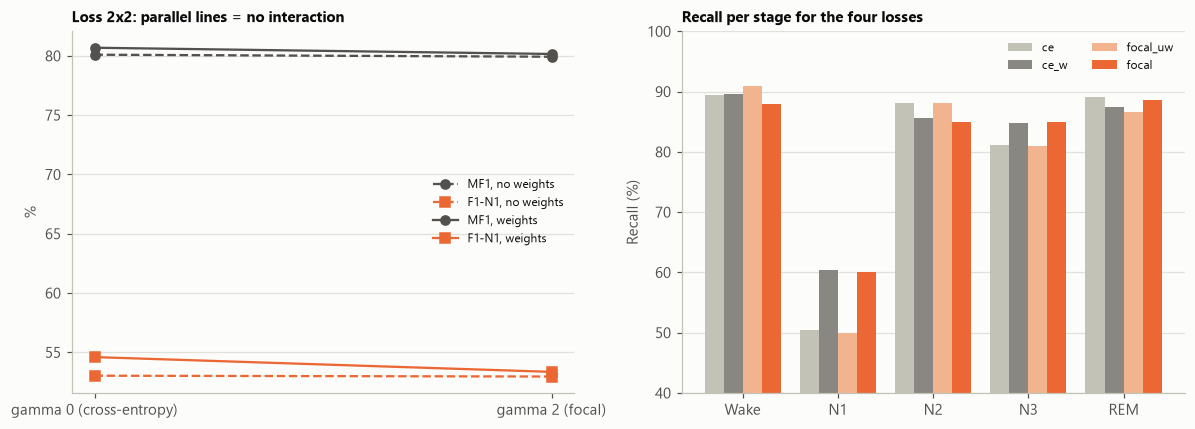

MF1 mean:
         no weights  weights
gamma 0        80.1     80.7
gamma 2        79.9     80.2

F1 N1:
         no weights  weights
gamma 0        53.0     54.6
gamma 2        53.0     53.4

F1 Wake:
         no weights  weights
gamma 0        91.0     91.4
gamma 2        91.6     90.8

F1 N2:
         no weights  weights
gamma 0        87.2     86.9
gamma 2        86.6     86.7

F1 N3:
         no weights  weights
gamma 0        82.0     82.7
gamma 2        81.8     82.5



,mean diff,CI low,CI high,better,subjects,p
class weights (average over gamma),0.367,-0.451,1.257,11.0,20.0,0.756
focusing gamma=2 (average over weights),-0.442,-1.022,0.133,7.0,20.0,0.231
interaction (weights effect at gamma 2 minus at gamma 0),-0.043,-1.279,1.073,11.0,20.0,0.869


In [8]:
# 2x2: focusing (gamma 0 / 2) x class weights (off / on), all other settings identical
cells = {("gamma 0", "no weights"): "ce", ("gamma 0", "weights"): "ce_w",
         ("gamma 2", "no weights"): "focal_uw", ("gamma 2", "weights"): "focal"}
grid = {m: pd.DataFrame({w: {g_: summary.loc[cells[(g_, w)], m] for g_ in ["gamma 0", "gamma 2"]}
                         for w in ["no weights", "weights"]}) for m in ["MF1 mean", "F1 N1", "F1 Wake", "F1 N2", "F1 N3"]}
ps = per_subject
contrasts = {
    "class weights (average over gamma)": sd.paired((ps["ce_w"] + ps["focal"]) / 2, (ps["ce"] + ps["focal_uw"]) / 2),
    "focusing gamma=2 (average over weights)": sd.paired((ps["focal_uw"] + ps["focal"]) / 2, (ps["ce"] + ps["ce_w"]) / 2),
    "interaction (weights effect at gamma 2 minus at gamma 0)": sd.paired(ps["focal"] - ps["focal_uw"] + ps["ce"], ps["ce_w"]),
}
contrast_table = pd.DataFrame(contrasts).T

recall = {arm: np.mean([np.diag(pd.crosstab(y_true, p, normalize="index").reindex(index=range(5), columns=range(5), fill_value=0))
                        for p in preds(arm)], axis=0) * 100 for arm in cells.values()}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for w, style in [("no weights", "--"), ("weights", "-")]:
    axes[0].plot([0, 2], [grid["MF1 mean"].loc[g_, w] for g_ in ["gamma 0", "gamma 2"]], style, marker="o", color=INK_2, label=f"MF1, {w}")
    axes[0].plot([0, 2], [grid["F1 N1"].loc[g_, w] for g_ in ["gamma 0", "gamma 2"]], style, marker="s", color=STAGE_COLORS["N1"], label=f"F1-N1, {w}")
axes[0].set_xticks([0, 2], ["gamma 0 (cross-entropy)", "gamma 2 (focal)"])
axes[0].set_ylabel("%")
axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Loss 2x2: parallel lines = no interaction", fontsize=10)
x = np.arange(5)
for k, arm in enumerate(cells.values()):
    axes[1].bar(x + (k - 1.5) * 0.2, recall[arm], width=0.2, label=arm,
                color=["#c3c2b7", "#898781", "#f2b48f", "#eb6834"][k])
axes[1].set_xticks(x, STAGES)
axes[1].set_ylim(40, 100)
axes[1].set_ylabel("Recall (%)")
axes[1].legend(frameon=False, fontsize=8, ncol=2)
axes[1].set_title("Recall per stage for the four losses", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_ablation_loss.png")
plt.show()
for m, t in grid.items():
    print(f"{m}:\n{t.round(1).to_string()}\n")
contrast_table.round(3)

**Output.** Tabel 2×2 dan dua grafik.

| MF1 | Tanpa bobot | Berbobot |
|---|---|---|
| γ = 0 (*cross-entropy*) | 80,1 | 80,7 |
| γ = 2 (*focal*) | 79,9 | 80,2 |

| F1-N1 | Tanpa bobot | Berbobot |
|---|---|---|
| γ = 0 | 53,0 | 54,6 |
| γ = 2 | 53,0 | 53,4 |

| Kontras (per subjek) | Selisih | Interval 95% | *p* |
|---|---|---|---|
| Bobot kelas (rerata atas γ) | +0,37 | −0,45 sampai +1,26 | 0,76 |
| γ = 2 (rerata atas bobot) | −0,44 | −1,02 sampai +0,13 | 0,23 |
| Interaksi | −0,04 | −1,28 sampai +1,07 | 0,87 |

Sensitivitas per tahap (%):

| | Wake | N1 | N2 | N3 | REM |
|---|---|---|---|---|---|
| Tanpa bobot, γ = 0 | 89,4 | 50,5 | 88,1 | 81,2 | 89,0 |
| Berbobot, γ = 0 | 89,6 | 60,4 | 85,7 | 84,9 | 87,5 |
| Tanpa bobot, γ = 2 | 90,9 | 49,9 | 88,0 | 81,0 | 86,6 |
| Berbobot, γ = 2 | 87,9 | 60,1 | 84,9 | 85,0 | 88,6 |

Pada N1, bobot kelas menaikkan porsi tebakan dari sekitar 6,0% ke 8,0–8,3% (porsi sebenarnya 6,6%), tetapi *precision* turun dari sekitar 56% ke 48–50%.

**Kesimpulan.**
1. **Tidak ada efek keseluruhan yang terbukti** dari bobot kelas, dari *focal loss*, maupun dari interaksinya. Kedua garis pada grafik kiri hampir sejajar, dan semua interval mencakup nol.
2. **Bobot kelas bekerja seperti menggeser ambang keputusan.** Model berbobot lebih sering menebak N1 dan N3, sehingga sensitivitas keduanya naik (N1 sekitar +10 poin) dengan harga *precision* N1 yang turun dan sensitivitas N2 yang turun 2–3 poin. Efek bersihnya pada F1-N1 hanya sekitar +1,6 poin (γ = 0) dan +0,4 (γ = 2), tanpa uji.
3. ***Focal loss* tidak menambah apa pun di atas bobot kelas.** Pada γ = 2, sensitivitas N1 dan N3 sama dengan *cross-entropy* berbobot, dan tanpa bobot sama dengan *cross-entropy* tanpa bobot. Kenaikan sensitivitas N1 dan N3 yang di notebook 04 tampak sebagai efek *focal loss* ternyata berasal dari bobot kelas.
4. **Pilihan** antara model tanpa bobot (lebih tepat) dan berbobot (lebih peka terhadap N1 dan N3) adalah soal kebutuhan aplikasi, bukan soal mutu keseluruhan. Konfigurasi referensi tetap dipertahankan; tidak ada alasan untuk mengubahnya.

## I. Konteks waktu dan panjang jendela

**Tujuan.** Mengukur seberapa penting konteks waktu: apakah Bi-LSTM perlu, dan jika perlu, berapa panjang jendela yang cukup.

**Input.** Empat percobaan: tanpa konteks (CNN saja, satu *epoch*), jendela 10, 20 (referensi), dan 30 *epoch*. Selain MF1 dan F1 per tahap, dihitung jumlah pergantian tahap per jam pada hasil prediksi, sebagai ukuran seberapa terpecah-pecah hipnogramnya. Untuk perbandingan, ukuran yang sama dihitung pada label pakar dan pada *baseline*.

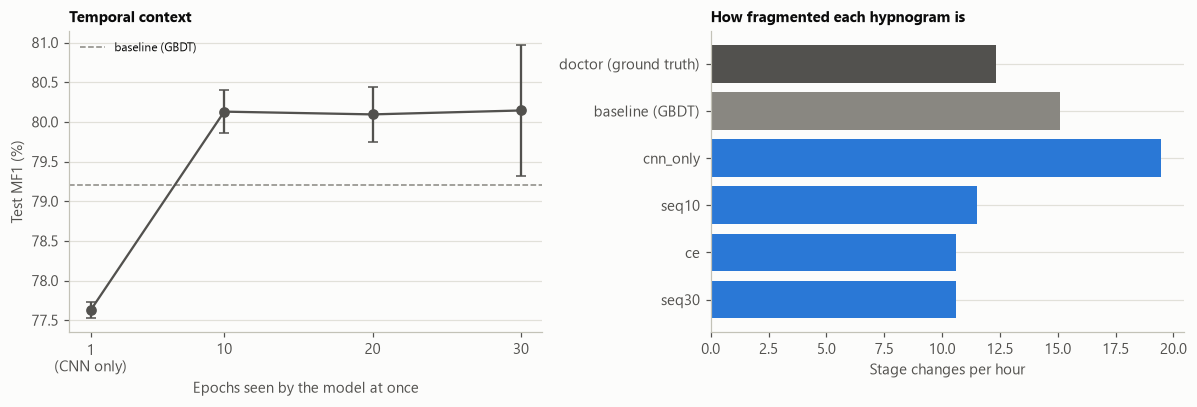

,context,MF1 mean,MF1 sd,F1 Wake,F1 N1,F1 N2,F1 N3,F1 REM,transitions per hour
cnn_only,none (1 epoch),77.6,0.1,88.9,47.1,86.3,82.6,83.2,19.5
seq10,10 epochs,80.1,0.3,91.4,53.7,87.1,81.8,86.6,11.5
ce,20 epochs (reference),80.1,0.4,91.0,53.0,87.2,82.0,87.2,10.6
seq30,30 epochs,80.1,0.8,91.4,53.8,86.9,80.7,87.9,10.6


In [9]:
rec_tested = rec_all[tested]


def transitions_per_hour(stages):
    """Stage changes per hour, for a sequence aligned with the tested epochs (labelled epochs only, so the
    few ignored epochs are skipped rather than counted as changes)."""
    changes = sum(np.sum(np.diff(stages[rec_tested == rec]) != 0) for rec in np.unique(rec_tested))
    return changes / (len(stages) * 30 / 3600)


frag = {"doctor (ground truth)": transitions_per_hour(y_true),
        "baseline (GBDT)": transitions_per_hour(base_pred[tested]),
        **{arm: np.mean([transitions_per_hour(p) for p in preds(arm)]) for arm in ["cnn_only", "seq10", "ce", "seq30"]}}
context = summary.loc[["cnn_only", "seq10", "ce", "seq30"], ["MF1 mean", "MF1 sd", "F1 Wake", "F1 N1", "F1 N2", "F1 N3", "F1 REM"]]
context.insert(0, "context", ["none (1 epoch)", "10 epochs", "20 epochs (reference)", "30 epochs"])
context["transitions per hour"] = [frag[a] for a in context.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
lengths = [1, 10, 20, 30]
axes[0].errorbar(lengths, context["MF1 mean"], yerr=context["MF1 sd"], marker="o", color=INK_2, capsize=3)
axes[0].axhline(100 * base_res["MF1"], color=MUTED, ls="--", lw=1, label="baseline (GBDT)")
axes[0].set_xticks(lengths, ["1\n(CNN only)", "10", "20", "30"])
axes[0].set_xlabel("Epochs seen by the model at once")
axes[0].set_ylabel("Test MF1 (%)")
axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Temporal context", fontsize=10)
axes[1].barh(list(frag), list(frag.values()), color=[INK_2, MUTED] + ["#2a78d6"] * 4)
axes[1].set_xlabel("Stage changes per hour")
axes[1].invert_yaxis()
axes[1].set_title("How fragmented each hypnogram is", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_ablation_context.png")
plt.show()
context.round(1)

**Output.**

| Konteks | MF1 | F1-Wake | F1-N1 | F1-N2 | F1-N3 | F1-REM | Pergantian tahap per jam |
|---|---|---|---|---|---|---|---|
| Tanpa (1 *epoch*) | 77,6 | 88,9 | 47,1 | 86,3 | 82,6 | 83,2 | 19,5 |
| 10 *epoch* | 80,1 | 91,4 | 53,7 | 87,1 | 81,8 | 86,6 | 11,5 |
| 20 *epoch* (referensi) | 80,1 | 91,0 | 53,0 | 87,2 | 82,0 | 87,2 | 10,6 |
| 30 *epoch* | 80,1 | 91,4 | 53,8 | 86,9 | 80,7 | 87,9 | 10,6 |

Sebagai pembanding, label pakar berganti tahap 12,3 kali per jam dan *baseline* 15,1 kali per jam.

**Kesimpulan.**
1. **Konteks waktu memberi kenaikan terbesar dan terbukti** (sekitar 2,5 poin MF1 antara tanpa konteks dan 10 *epoch*; bagian G). Kenaikan terbesar ada pada REM (+3,4 poin), N1 (+6,6), dan Wake (+2,5). Pada ketiganya satu *epoch* sering ambigu, dan tetangga di sekitarnya membantu memutuskan. N3 hampir tidak terpengaruh.
2. **Konteks 10 *epoch* (5 menit) sudah cukup.** Menambah ke 20 atau 30 tidak mengubah MF1 (selisih +0,01 dan −0,03 poin per subjek). Jendela 30 hanya membuat hasil antar-*seed* lebih bervariasi (simpangan baku 0,8 dibanding 0,3–0,4).
3. **Konteks juga membuat hasil lebih halus.** Tanpa konteks, prediksi berganti tahap 19,5 kali per jam, jauh lebih sering daripada pakar (12,3). Dengan Bi-LSTM, angkanya 10,6–11,5, sedikit di bawah pakar. Model dengan konteks cenderung terlalu mulus, mungkin karena ikut meratakan perubahan singkat yang sebenarnya nyata. Dugaan ini belum diuji.

## J. Sinyal masukan

**Tujuan.** Melihat apa yang disumbangkan tiap jenis sinyal ketika ditambahkan satu per satu: EEG Fpz-Cz, lalu EEG Pz-Oz, lalu EOG, lalu EMG. Hasilnya juga dibandingkan dengan percobaan serupa pada *baseline* (notebook 03), untuk melihat apakah model *deep learning* memanfaatkan sinyal secara berbeda.

**Input.** Empat percobaan sinyal bertingkat dan tabel ablasi *baseline*. Keputusan terbuka tentang kanal kedua EEG diuji secara terpisah: selisih berpasangan antara model dengan dua kanal EEG dan dengan satu kanal.

K2 (second EEG channel, EEG-only models): +0.57 points per subject (95% CI -0.34 to +1.51), better for 12 of 20, p = 0.2611


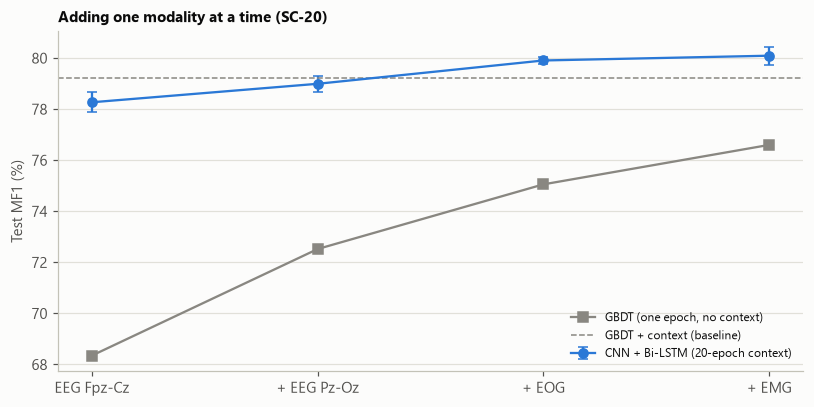

,CNN + Bi-LSTM MF1,CNN + Bi-LSTM sd,CNN F1-N1,CNN F1-REM,GBDT MF1 (no context),CNN step,GBDT step
EEG Fpz-Cz,78.3,0.4,48.0,85.5,68.4,NaN,NaN
+ EEG Pz-Oz,79.0,0.3,52.2,83.7,72.5,0.7,4.2
+ EOG,79.9,0.1,54.7,85.4,75.1,0.9,2.5
+ EMG,80.1,0.4,53.0,87.2,76.6,0.2,1.5


In [10]:
gbdt = pd.read_csv(BASELINE_ABLATION, index_col=0)
ladder = pd.DataFrame({
    "CNN + Bi-LSTM MF1": [summary.loc[a, "MF1 mean"] for a in ["eeg_fpz", "eeg_2ch", "eeg_eog", "ce"]],
    "CNN + Bi-LSTM sd": [summary.loc[a, "MF1 sd"] for a in ["eeg_fpz", "eeg_2ch", "eeg_eog", "ce"]],
    "CNN F1-N1": [summary.loc[a, "F1 N1"] for a in ["eeg_fpz", "eeg_2ch", "eeg_eog", "ce"]],
    "CNN F1-REM": [summary.loc[a, "F1 REM"] for a in ["eeg_fpz", "eeg_2ch", "eeg_eog", "ce"]],
    "GBDT MF1 (no context)": (100 * gbdt["MF1"].iloc[:4]).values,
}, index=["EEG Fpz-Cz", "+ EEG Pz-Oz", "+ EOG", "+ EMG"])
ladder["CNN step"] = ladder["CNN + Bi-LSTM MF1"].diff()
ladder["GBDT step"] = ladder["GBDT MF1 (no context)"].diff()
k2 = sd.paired(per_subject["eeg_2ch"], per_subject["eeg_fpz"])
print(f"K2 (second EEG channel, EEG-only models): {k2['mean diff']:+.2f} points per subject "
      f"(95% CI {k2['CI low']:+.2f} to {k2['CI high']:+.2f}), better for {k2['better']} of {k2['subjects']}, "
      f"p = {k2['p']:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
xs = np.arange(4)
ax.errorbar(xs, ladder["CNN + Bi-LSTM MF1"], yerr=ladder["CNN + Bi-LSTM sd"], marker="o", color="#2a78d6",
            capsize=3, label="CNN + Bi-LSTM (20-epoch context)")
ax.plot(xs, ladder["GBDT MF1 (no context)"], marker="s", color=MUTED, label="GBDT (one epoch, no context)")
ax.axhline(100 * gbdt["MF1"].iloc[4], color=MUTED, ls="--", lw=1, label="GBDT + context (baseline)")
ax.set_xticks(xs, ladder.index)
ax.set_ylabel("Test MF1 (%)")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Adding one modality at a time (SC-20)", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_ablation_modality.png")
plt.show()
ladder.round(1)

**Output.**
- Kanal kedua EEG: +0,57 poin per subjek (interval 95% −0,34 sampai +1,51), membaik pada 12 dari 20 subjek, *p* = 0,26.

| Sinyal | CNN + Bi-LSTM MF1 | Langkah | GBDT tanpa konteks | Langkah | F1-N1 | F1-REM |
|---|---|---|---|---|---|---|
| EEG Fpz-Cz | 78,3 | | 68,4 | | 48,0 | 85,5 |
| + EEG Pz-Oz | 79,0 | +0,7 | 72,5 | +4,2 | 52,2 | 83,7 |
| + EOG | 79,9 | +0,9 | 75,1 | +2,5 | 54,7 | 85,4 |
| + EMG | 80,1 | +0,2 | 76,6 | +1,5 | 53,0 | 87,2 |

**Kesimpulan.**
1. **Model *deep learning* jauh lebih tahan terhadap hilangnya sinyal.** Dengan hanya satu kanal EEG, ia mencapai MF1 78,3, sedangkan *gradient boosting* hanya 68,4. Penambahan sinyal pada model *deep learning* menaikkan skor 0,2–0,9 poin per langkah, dibanding 1,5–4,2 poin pada *gradient boosting*.
2. **Penjelasannya belum pasti.** Salah satu dugaan: konteks 20 *epoch* menutupi sebagian informasi yang hilang. Pembandingan yang adil ada pada percobaan tanpa konteks. Dengan semua sinyal tanpa konteks, CNN mencapai 77,6 dan *gradient boosting* 76,6, sehingga selisihnya hanya sekitar 1 poin (tanpa uji). Kolom *gradient boosting* di tabel memang tanpa konteks, jadi selisih antar-kolom bercampur dengan efek konteks.
3. **EMG hampir tidak menaikkan MF1 keseluruhan** (+0,2, tidak terbukti), tetapi menaikkan F1-REM 1,8 poin (85,4 ke 87,2) dengan harga F1-N1 yang turun 1,7. Pola ini sejalan dengan fungsi EMG pada tidur REM (otot melemas), yang juga terlihat pada *baseline* di notebook 03. Dengan 20 subjek, efek sekecil itu tidak dapat dipastikan.
4. **Kanal kedua EEG belum terbukti membantu, dan juga tidak terbukti merugikan.** Model akhir tetap memakai dua kanal (alasan teknis di catatan di bawah).

## K. Kebocoran data pada model akhir

**Tujuan.** Mengukur seberapa besar skor menggelembung jika data dibagi acak per *epoch* alih-alih per subjek, memakai model akhir. Sebelumnya pengukuran ini hanya dilakukan pada *baseline* klasik.

**Input.** Hasil percobaan pembagian acak per *epoch* (satu *seed*), dibandingkan dengan hasil per subjek *seed* yang sama. Pembanding untuk *baseline* diambil dari notebook 03.

In [11]:
leak_runs = [runs[("leak", s)] for s in LEAK_SEEDS]
done = np.all([~np.isnan(r["probs"][:, 0]) for r in leak_runs], axis=0) & scored
leak_res = sd.summarise(labels_all[done], np.mean([r["probs"][done] for r in leak_runs], axis=0).argmax(1))
ref_res = {s: sd.summarise(y_true, runs[("ce", s)]["probs"][tested].argmax(1)) for s in SEEDS}
gbdt_leak = pd.read_csv(BASELINE_LEAKAGE, index_col=0)
cols = ["ACC", "MF1", "F1_N1", "kappa"]
leakage = pd.DataFrame({
    "CNN by subject (seed 0)": {c: ref_res[LEAK_SEEDS[0]][c] for c in cols},
    "CNN by epoch (leaky, seed 0)": {c: leak_res[c] for c in cols},
    "GBDT by subject": gbdt_leak.loc["by subject (correct)", cols].to_dict(),
    "GBDT by epoch (leaky)": gbdt_leak.loc["by epoch (leaky)", cols].to_dict()}).T
leakage.loc[:, ["ACC", "MF1", "F1_N1"]] *= 100
print(f"leaky split inflates MF1 by {leakage.iloc[1]['MF1'] - leakage.iloc[0]['MF1']:+.1f} points for the CNN and "
      f"{leakage.iloc[3]['MF1'] - leakage.iloc[2]['MF1']:+.1f} for the GBDT; "
      f"{done.sum():,} of {scored.sum():,} epochs tested in the leaky run")
leakage.round({"ACC": 1, "MF1": 1, "F1_N1": 1, "kappa": 3})

leaky split inflates MF1 by +10.2 points for the CNN and +7.0 for the GBDT; 42,307 of 42,307 epochs tested in the leaky run


,ACC,MF1,F1_N1,kappa
CNN by subject (seed 0),85.1,80.4,54.2,0.796
"CNN by epoch (leaky, seed 0)",93.3,90.6,75.4,0.908
GBDT by subject,84.1,79.2,49.3,0.784
GBDT by epoch (leaky),90.0,86.2,63.6,0.863


**Output.** Semua 42.307 *epoch* berlabel teruji pada pembagian acak.

| | Akurasi | MF1 | F1-N1 | κ |
|---|---|---|---|---|
| CNN + Bi-LSTM, per subjek | 85,1 | 80,4 | 54,2 | 0,796 |
| CNN + Bi-LSTM, per *epoch* (bocor) | 93,3 | 90,6 | 75,4 | 0,908 |
| *Baseline*, per subjek | 84,1 | 79,2 | 49,3 | 0,784 |
| *Baseline*, per *epoch* (bocor) | 90,0 | 86,2 | 63,6 | 0,863 |

**Kesimpulan.**
1. **Pembagian acak menggelembungkan MF1 sebesar 10,2 poin pada CNN + Bi-LSTM dan 7,0 poin pada *baseline*.** Skor 90,6 di atas tidak bisa dibandingkan dengan literatur yang memakai pembagian per subjek.
2. **Model yang lebih besar terkena lebih parah.** Dugaan penyebabnya: model dengan kapasitas besar dan konteks panjang lebih mudah menghafal ciri khas satu malam rekaman, dan pada pembagian acak *epoch* tetangga dari malam yang sama ada di data latih. Dugaan ini belum diuji.
3. **N1 paling terdampak** (F1 naik 21,2 poin). Itu wajar, karena N1 tahap yang paling sulit dan paling bergantung pada ciri khas orang.
4. Hanya satu *seed* yang dijalankan. Karena selisihnya (10 poin) jauh di atas variasi antar-*seed* (simpangan baku sekitar 0,4), kesimpulan arah dan besarnya tidak terpengaruh.

## L. Penyimpanan

**Tujuan.** Menyimpan semua tabel agar angka di notebook ini bisa dirujuk tanpa menjalankan ulang pelatihan.

**Input.** Tabel ringkasan, uji berpasangan, 2×2, konteks, sinyal, kebocoran, dan MF1 per subjek.

In [12]:
per_run.to_csv(TAB_DIR / "06_ablation_runs.csv", index=False)
summary.to_csv(TAB_DIR / "06_ablation_summary.csv")
paired_table.to_csv(TAB_DIR / "06_ablation_paired.csv")
pd.concat({m: t for m, t in grid.items()}).to_csv(TAB_DIR / "06_ablation_loss_grid.csv")
contrast_table.to_csv(TAB_DIR / "06_ablation_loss_contrasts.csv")
context.to_csv(TAB_DIR / "06_ablation_context.csv")
ladder.to_csv(TAB_DIR / "06_ablation_modality.csv")
leakage.to_csv(TAB_DIR / "06_ablation_leakage.csv")
per_subject.to_csv(TAB_DIR / "06_ablation_per_subject.csv")
print("tables:", sorted(p.name for p in TAB_DIR.glob("06_ablation_*.csv")))
print(f"GPU time of the new arms: {per_run[~per_run['arm'].isin(REUSED)]['minutes'].sum() / 60:.1f} h"
      + (f" + leaky run {sum(runs[('leak', s)]['minutes'] for s in LEAK_SEEDS) / 60:.1f} h" if ('leak', 0) in runs else ""))

tables: ['06_ablation_context.csv', '06_ablation_leakage.csv', '06_ablation_loss_contrasts.csv', '06_ablation_loss_grid.csv', '06_ablation_modality.csv', '06_ablation_paired.csv', '06_ablation_per_subject.csv', '06_ablation_runs.csv', '06_ablation_summary.csv']
GPU time of the new arms: 11.9 h + leaky run 1.7 h


**Output.** Sembilan berkas CSV di `results/tables/` dan tiga gambar di `results/figures/`, awalan `06_`.

**Kesimpulan.** Seluruh angka di notebook ini dapat ditelusuri ke berkas tersebut.

## Kesimpulan

1. **Konteks waktu adalah komponen yang terbukti.** Menghilangkan Bi-LSTM menurunkan MF1 sekitar 2,3 poin per subjek (*p* terkoreksi 0,001), terutama pada REM, N1, dan Wake. Jendela 10 *epoch* (5 menit) sudah cukup.
2. ***Loss* dan bobot kelas tidak mengubah mutu keseluruhan** (semua selisih tidak signifikan). Bobot kelas menggeser keseimbangan: N1 dan N3 lebih sering terdeteksi dengan harga *precision*. *Focal loss* tidak menambah apa pun di atas bobot kelas.
3. **Sinyal tambahan membantu pelan-pelan.** Dari satu kanal EEG (78,3) ke semua sinyal (80,1), tetapi setelah koreksi tidak ada model dengan sinyal lebih sedikit yang terbukti lebih buruk daripada model lengkap. Kontribusi EMG terlihat pada REM, bukan pada MF1 keseluruhan.
4. **Kebocoran data menggelembungkan MF1 sebesar 10,2 poin** pada model akhir (7,0 pada *baseline*).
5. **Model referensi tidak diubah.** Tidak ada percobaan yang terbukti lebih baik darinya, dan konfigurasi untuk benchmark 78 subjek sudah dibekukan sebelum ablasi ini selesai.

## Keterbatasan

- **Daya uji rendah.** Dengan 20 subjek, lebar interval kepercayaan sekitar ±1 poin. Selisih lebih kecil dari itu tidak dapat dideteksi, sehingga "tidak signifikan" di sini berarti "tidak terbukti", bukan "tidak ada pengaruh".
- **Hanya subjek muda.** Seluruh subjek berusia 25–34 tahun. Pola tidur dan mutu sinyal berubah menurut usia (notebook 05), sehingga temuan di sini belum tentu berlaku untuk kelompok usia lain. Percobaan konfirmasi pada 78 subjek tidak dijalankan, karena biayanya sekitar dua kali lipat dan hasilnya tidak mengubah konfigurasi yang sudah dibekukan. Temuan ini karenanya hanya berlaku untuk 20 subjek ini.
- **Satu pembagian subjek untuk semua percobaan.** Semua percobaan memakai 20 subjek uji yang sama, jadi ablasi menjelaskan peran komponen, bukan memilih model.
- **Tangga sinyal bersifat berurutan.** Kontribusi EMG diukur setelah EEG dan EOG sudah ada. Urutan lain bisa memberi angka berbeda.
- **Perbandingan dengan *baseline* pada tangga sinyal tidak sepadan.** *Gradient boosting* di tabel J tanpa konteks, sedangkan CNN + Bi-LSTM memakai 20 *epoch*.
- **Beberapa kesimpulan berupa dugaan:** penyebab model lebih tahan terhadap hilangnya sinyal, penyebab kebocoran lebih parah pada model besar, dan kecenderungan model terlalu mulus. Ketiganya belum diuji langsung.
- **Percobaan kebocoran hanya satu *seed*.** Selisihnya (10 poin) jauh di atas variasi antar-*seed*, tetapi besarnya yang pasti tidak diketahui.

## Catatan teknis

- **Berkas:** hasil per *run* di `data/processed/ablation_sc20_runs/` (tidak masuk git); percobaan *cross-entropy* tanpa bobot dan *focal* berbobot dimuat dari `data/processed/cnn_sc20_runs/` (notebook 04). Tabel dan gambar berawalan `06_`.
- **Kode keputusan:** rancangan ini adalah K8. Hasilnya menutup K2 (jumlah kanal EEG) dan K3 (kebocoran pada model akhir) di `docs/catatan/KEPUTUSAN_DESAIN.md`.
- **Nama percobaan di kode:** `ce` (referensi), `focal`, `ce_w`, `focal_uw`, `cnn_only`, `seq10`, `seq30`, `eeg_fpz`, `eeg_2ch`, `eeg_eog`, `leak`.
- **Bobot kelas pada `ce_w`** dihitung sebagai rerata suku *cross-entropy* berbobot (bukan rerata berbobot bawaan PyTorch). Dengan begitu `ce_w` sama dengan *focal* pada γ = 0, dan keempat sel 2×2 hanya berbeda pada γ dan bobot.
- **Panjang jendela:** pada jendela 10 dan 30 jumlah jendela per *batch* disesuaikan (64 dan 21) agar jumlah *epoch* per *batch* tetap sekitar 640 (jendela 30: 630), sehingga jumlah langkah optimasi per putaran latih hampir sama.
- **Dua kanal EEG dipertahankan** karena sudah dipakai pada model referensi dan pada benchmark 78 subjek, dan karena penambahan kanal kedua tidak merugikan (+0,57, tidak signifikan).
- **Proses sempat terhenti** beberapa kali karena RAM laptop menipis dan karena laptop masuk mode tidur, lalu dilanjutkan dari *fold* tersimpan. Waktu per *run* di log dapat mencakup bagian yang dilanjutkan, sehingga total waktu GPU adalah perkiraan.
- **Referensi:** notebook 01 (istilah), 03 (*baseline* dan ablasi sinyal *baseline*), 04 (model referensi), 05 (benchmark 78 subjek).